In [ ]:

import requests
import json
from pathlib import Path

# 1. Request a small sample from OpenAlex
url = "https://api.openalex.org/works"

params = {
    "search": '"artificial intelligence" education',
    "filter": "from_publication_date:2020-01-01",
    "per_page": 10,
    "page": 1
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

# 2. Convert the API response into Python data
result = response.json()

print("Total matching records:", result["meta"]["count"])
print("Papers downloaded:", len(result["results"]))

# 3. Create the raw data folder
output_folder = Path("data/raw/openalex")
output_folder.mkdir(parents=True, exist_ok=True)

# 4. Save the complete API response
output_file = output_folder / "openalex_test_sample.json"

with open(output_file, "w", encoding="utf-8") as file:
    json.dump(result, file, ensure_ascii=False, indent=2)

print("Saved successfully!")
print("File location:", output_file.resolve())


In [ ]:

import json
from pathlib import Path

# Find the raw file we saved
file_path = Path("data/raw/openalex/openalex_test_sample.json")

# Read the file
with open(file_path, "r", encoding="utf-8") as file:
    saved_data = json.load(file)

# Check the saved data
print("Total matching records:", saved_data["meta"]["count"])
print("Papers saved:", len(saved_data["results"]))

print("\nFirst paper title:")
print(saved_data["results"][0].get("title"))


In [ ]:

papers = saved_data["results"]

fields = [
    "id",
    "title",
    "publication_year",
    "doi",
    "authorships",
    "primary_location"
]

print("DATA QUALITY REPORT")
print("=" * 35)

for field in fields:
    missing = sum(
        1 for paper in papers
        if paper.get(field) is None
        or paper.get(field) == ""
        or paper.get(field) == []
    )

    percentage = missing / len(papers) * 100

    print(
        f"{field}: {missing}/{len(papers)} missing "
        f"({percentage:.1f}%)"
    )


In [ ]:

for paper in papers:
    if not paper.get("authorships"):
        print("Paper with missing authorship information")
        print("Title:", paper.get("title"))
        print("OpenAlex ID:", paper.get("id"))
        print("Year:", paper.get("publication_year"))
        print("DOI:", paper.get("doi"))


In [ ]:

for paper in papers:
    authorships = paper.get("authorships") or []

    authors_without_institutions = 0
    institutions_without_country = 0

    for authorship in authorships:
        institutions = authorship.get("institutions") or []

        if not institutions:
            authors_without_institutions += 1

        for institution in institutions:
            if not institution.get("country_code"):
                institutions_without_country += 1

    print("\nTitle:", paper.get("title"))
    print("Authors:", len(authorships))
    print("Authors without institutions:", authors_without_institutions)
    print("Institutions without country:", institutions_without_country)


In [ ]:
EU_COUNTRIES = {
    "AT","BE","BG","HR","CY","CZ","DK",
    "EE","FI","FR","DE","GR","HU","IE",
    "IT","LV","LT","LU","MT","NL","PL",
    "PT","RO","SK","SI","ES","SE"
}

total_papers = len(papers)

papers_with_institution = 0
papers_with_eu = 0
papers_unknown = 0


for paper in papers:

    has_institution = False
    has_eu = False

    for authorship in paper.get("authorships", []):

        for institution in authorship.get("institutions", []):

            has_institution = True

            country = institution.get("country_code")

            if country in EU_COUNTRIES:
                has_eu = True


    if has_institution:
        papers_with_institution += 1

    if has_eu:
        papers_with_eu += 1

    if not has_institution:
        papers_unknown += 1


print("Total papers:", total_papers)
print("Papers with institution:", papers_with_institution)
print("Papers with EU affiliation:", papers_with_eu)
print("Papers with unknown affiliation:", papers_unknown)

In [ ]:
for paper in papers:
    has_institution = any(
        authorship.get("institutions")
        for authorship in (paper.get("authorships") or [])
    )

    if not has_institution:
        print(paper.get("title"))

In [ ]:
import requests

url = "https://api.openalex.org/works"

params = {
    "filter": (
        "from_publication_date:2020-01-01,"
        "title.search:artificial intelligence education"
    ),
    "per_page": 10,
    "page": 1
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

result = response.json()

print("Total matching results:", result["meta"]["count"])
print("\nSample titles:")

for paper in result["results"]:
    print("-", paper.get("title"))

In [ ]:
years = [
    paper.get("publication_year")
    for paper in result["results"]
]

print("Oldest year in this sample:", min(years))
print("Newest year in this sample:", max(years))
print("Publication years:", sorted(set(years)))

In [ ]:
import requests

url = "https://api.openalex.org/works"

for year in range(2020, 2027):
    params = {
        "filter": (
            f"from_publication_date:{year}-01-01,"
            f"to_publication_date:{year}-12-31,"
            "title.search:artificial intelligence education"
        ),
        "per_page": 1
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()
    data = response.json()

    print(year, ":", data["meta"]["count"], "records")

In [ ]:
import requests

url = "https://api.openalex.org/works"

params = {
    "filter": (
        "from_publication_date:2020-01-01,"
        "title.search:artificial intelligence education"
    ),
    "per_page": 20,
    "page": 1
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

result = response.json()

for i, paper in enumerate(result["results"], start=1):
    print(f"{i}. {paper.get('title')}")

In [ ]:
for i, paper in enumerate(result["results"], start=1):
    print(f"\n{i}. {paper.get('title')}")
    print("Abstract:", paper.get("abstract"))

In [ ]:
for i, paper in enumerate(result["results"], start=1):
    print(f"\n{i}. {paper.get('title')}")
    print("DOI:", paper.get("doi"))
    print("Year:", paper.get("publication_year"))
    print("Authors:", len(paper.get("authorships") or []))
    print("Venue:", (paper.get("primary_location") or {}).get("source", {}).get("display_name")
          if (paper.get("primary_location") or {}).get("source") else "Missing")

In [ ]:
def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return None

    words = []

    for word, positions in inverted_index.items():
        for position in positions:
            words.append((position, word))

    words.sort(key=lambda item: item[0])

    return " ".join(word for position, word in words)


for i, paper in enumerate(result["results"], start=1):
    abstract = reconstruct_abstract(
        paper.get("abstract_inverted_index")
    )

    print(f"\n{i}. {paper.get('title')}")

    if abstract:
        print("Abstract:", abstract[:700])
    else:
        print("Abstract unavailable in OpenAlex")

In [ ]:
import pandas as pd

classification = [
    {
        "title": "Artificial Intelligence, Education, and Entrepreneurship",
        "decision": "exclude",
        "reason": "Focuses on AI professors and startup outcomes"
    },
    {
        "title": "Broadening artificial intelligence education in K-12",
        "decision": "include",
        "reason": "Directly concerns AI education in schools"
    },
    {
        "title": "The role of learners' competencies in artificial intelligence education",
        "decision": "include",
        "reason": "Studies competencies for learning AI"
    },
    {
        "title": "Teachers' Perspective on Artificial Intelligence Education: an Initial Investigation",
        "decision": "include",
        "reason": "Studies teachers' perspectives on AI education"
    },
    {
        "title": "Artificial Intelligence Education Programs for Health Care Professionals: Scoping Review",
        "decision": "review",
        "reason": "Healthcare professional training; scope needs clarification"
    }
]

classification_df = pd.DataFrame(classification)
classification_df

In [ ]:
for i, paper in enumerate(result["results"][:5], start=1):
    print(f"\nPaper {i}")
    print("OpenAlex ID:", paper.get("id"))
    print("Title:", paper.get("title"))

In [ ]:
# Map each OpenAlex ID to our classification
decisions = {
    "https://openalex.org/W4389607940": (
        "exclude",
        "Focuses on AI professors and startup outcomes"
    ),
    "https://openalex.org/W3006030984": (
        "include",
        "Directly concerns AI education in schools"
    ),
    "https://openalex.org/W4296184066": (
        "include",
        "Studies competencies for learning AI"
    ),
    "https://openalex.org/W4225141765": (
        "include",
        "Studies teachers' perspectives on AI education"
    ),
    "https://openalex.org/W4200037840": (
        "review",
        "Healthcare professional training; scope needs clarification"
    )
}

# Add the decisions to the original OpenAlex records
classified_papers = []

for paper in result["results"][:5]:
    paper_id = paper.get("id")

    if paper_id in decisions:
        decision, reason = decisions[paper_id]

        classified_papers.append({
            "openalex_id": paper_id,
            "title": paper.get("title"),
            "publication_year": paper.get("publication_year"),
            "doi": paper.get("doi"),
            "decision": decision,
            "reason": reason
        })

classification_df = pd.DataFrame(classified_papers)

classification_df

In [ ]:
# Map each OpenAlex ID to our classification
decisions = {
    "https://openalex.org/W4389607940": (
        "exclude",
        "Focuses on AI professors and startup outcomes"
    ),
    "https://openalex.org/W3006030984": (
        "include",
        "Directly concerns AI education in schools"
    ),
    "https://openalex.org/W4296184066": (
        "include",
        "Studies competencies for learning AI"
    ),
    "https://openalex.org/W4225141765": (
        "include",
        "Studies teachers' perspectives on AI education"
    ),
    "https://openalex.org/W4200037840": (
        "review",
        "Healthcare professional training; scope needs clarification"
    )
}

# Add the decisions to the original OpenAlex records
classified_papers = []

for paper in result["results"][:5]:
    paper_id = paper.get("id")

    if paper_id in decisions:
        decision, reason = decisions[paper_id]

        classified_papers.append({
            "openalex_id": paper_id,
            "title": paper.get("title"),
            "publication_year": paper.get("publication_year"),
            "doi": paper.get("doi"),
            "decision": decision,
            "reason": reason
        })

classification_df = pd.DataFrame(classified_papers)

classification_df

In [ ]:
from pathlib import Path

# Create a folder for processed data if it doesn't exist
output_folder = Path("data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# Save the five classified papers
output_file = output_folder / "paper_classification_sample.csv"
classification_df.to_csv(output_file, index=False)

print(f"Saved to: {output_file}")
print(f"Number of papers saved: {len(classification_df)}")

In [28]:
from pathlib import Path

print("Current working folder:")
print(Path.cwd())

for folder in ["data/raw/openalex", "data/processed"]:
    path = Path(folder)

    print(f"\n{folder}")

    if path.exists():
        files = list(path.iterdir())
        if files:
            for file in files:
                print("  ", file.name)
        else:
            print("  Folder is empty")
    else:
        print("  Folder does not exist")

Current working folder:
c:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\data\raw

data/raw/openalex
   openalex_test_sample.json

data/processed
   paper_classification_sample.csv


In [31]:
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

for filename in ["openalex_test_sample.json", "paper_classification_sample.csv"]:
    matches = list(project.rglob(filename))
    print(f"\n{filename}:")

    if matches:
        for match in matches:
            print(match)
    else:
        print("Not found inside project folder")


openalex_test_sample.json:
C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\data\raw\openalex\openalex_test_sample.json
C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\data\raw\data\raw\openalex\openalex_test_sample.json

paper_classification_sample.csv:
C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\data\raw\data\processed\paper_classification_sample.csv


In [32]:
import json
from pathlib import Path

json_path = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\data\raw\openalex\openalex_test_sample.json"
)

with open(json_path, "r", encoding="utf-8") as f:
    data = json.load(f)

papers = data.get("results", [])

print("Sample loaded successfully!")
print("Number of papers:", len(papers))
print("Total OpenAlex search results:", data.get("meta", {}).get("count"))

if papers:
    print("\nFirst paper title:")
    print(papers[0].get("title"))

Sample loaded successfully!
Number of papers: 10
Total OpenAlex search results: 936363

First paper title:
Correction: Impact of artificial intelligence on human loss in decision making, laziness and safety in education


In [33]:
import requests

url = "https://api.openalex.org/works"

params = {
    "filter": "from_publication_date:2020-01-01",
    "search": '"artificial intelligence" education',
    "per_page": 5,
    "page": 1
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

search_data = response.json()

print("Results reported:", search_data["meta"]["count"])
print("\nFirst five titles:\n")

for paper in search_data["results"]:
    print(
        paper.get("publication_year"),
        "-",
        paper.get("title")
    )

Results reported: 938188

First five titles:

2023 - Correction: Impact of artificial intelligence on human loss in decision making, laziness and safety in education
2020 - ARTIFICIAL INTELLIGENCE AND EDUCATION
2024 - Artificial Intelligence and Education
2023 - Artificial Intelligence in Education
2023 - Artificial Intelligence and Education


In [34]:
# Inspect the first paper's basic information
paper = search_data["results"][0]

print("Title:", paper.get("title"))
print("Year:", paper.get("publication_year"))
print("\nAuthors and affiliations:")

for authorship in paper.get("authorships", []):
    author = authorship.get("author", {})
    print("\nAuthor:", author.get("display_name"))

    institutions = authorship.get("institutions", [])

    if institutions:
        for institution in institutions:
            print("Institution:", institution.get("display_name"))
            print("Country:", institution.get("country_code"))
    else:
        print("No institution listed")

Title: Correction: Impact of artificial intelligence on human loss in decision making, laziness and safety in education
Year: 2023

Authors and affiliations:

Author: Sayed Fayaz Ahmad
Institution: Institute of Business Management
Country: PK

Author: Heesup Han
Institution: Sejong University
Country: KR

Author: Muhammad Mansoor Alam
Institution: Riphah International University
Country: PK

Author: Mohd. Khairul Rehmat
Institution: University of Kuala Lumpur
Country: MY

Author: Muhammad Irshad
No institution listed

Author: Marcelo Arraño-Muñoz
Institution: Universidad de Playa Ancha de Ciencias de la Educación
Country: CL

Author: Antonio Ariza‐Montes
Institution: Universidad Loyola Andalucía
Country: ES


In [35]:

EU_COUNTRIES = {
    "AT", "BE", "BG", "HR", "CY", "CZ", "DK",
    "EE", "FI", "FR", "DE", "GR", "HU", "IE",
    "IT", "LV", "LT", "LU", "MT", "NL", "PL",
    "PT", "RO", "SK", "SI", "ES", "SE"
}

def get_eu_countries(paper):
    countries = set()

    for authorship in paper.get("authorships", []):
        for institution in authorship.get("institutions", []):
            country = institution.get("country_code")

            if country in EU_COUNTRIES:
                countries.add(country)

    return sorted(countries)


for paper in search_data["results"]:
    eu_countries = get_eu_countries(paper)

    print("\nTitle:", paper.get("title"))
    print("Year:", paper.get("publication_year"))
    print("EU countries:", eu_countries)

    if eu_countries:
        print("Initial EU test: PASS")
    else:
        print("Initial EU test: NO EU affiliation found")



Title: Correction: Impact of artificial intelligence on human loss in decision making, laziness and safety in education
Year: 2023
EU countries: ['ES']
Initial EU test: PASS

Title: ARTIFICIAL INTELLIGENCE AND EDUCATION
Year: 2020
EU countries: []
Initial EU test: NO EU affiliation found

Title: Artificial Intelligence and Education
Year: 2024
EU countries: []
Initial EU test: NO EU affiliation found

Title: Artificial Intelligence in Education
Year: 2023
EU countries: []
Initial EU test: NO EU affiliation found

Title: Artificial Intelligence and Education
Year: 2023
EU countries: []
Initial EU test: NO EU affiliation found


In [36]:

import pandas as pd
from pathlib import Path

rows = []

for paper in search_data["results"]:
    eu_countries = get_eu_countries(paper)

    rows.append({
        "openalex_id": paper.get("id"),
        "title": paper.get("title"),
        "publication_year": paper.get("publication_year"),
        "type": paper.get("type"),
        "doi": paper.get("doi"),
        "eu_countries": "; ".join(eu_countries),
        "has_eu_affiliation": bool(eu_countries)
    })

test_df = pd.DataFrame(rows)

output_folder = Path("data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "eu_affiliation_test.csv"
test_df.to_csv(output_file, index=False)

print("Saved file:", output_file.resolve())
print("Rows saved:", len(test_df))

display(test_df)


Saved file: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\data\raw\data\processed\eu_affiliation_test.csv
Rows saved: 5


,openalex_id,title,publication_year,type,doi,eu_countries,has_eu_affiliation
0,https://openalex.org/W4382722418,Correction: Impact of artificial intelligence ...,2023,erratum,https://doi.org/10.1057/s41599-023-01842-4,ES,True
1,https://openalex.org/W4403333411,ARTIFICIAL INTELLIGENCE AND EDUCATION,2020,book-chapter,https://doi.org/10.25215/9358094575.32,,False
2,https://openalex.org/W4393379282,Artificial Intelligence and Education,2024,article,https://doi.org/10.37437/2222517x-2024-123-2-1-68,,False
3,https://openalex.org/W4404977879,Artificial Intelligence in Education,2023,article,https://doi.org/10.37314/jjem.sp0125,,False
4,https://openalex.org/W2292347285,Artificial Intelligence and Education,2023,book-chapter,https://doi.org/10.5771/9781475871944-11,,False


In [37]:

# 1. Check the types of documents
print("Document types:")
display(test_df["type"].value_counts(dropna=False).to_frame("count"))

# 2. Check for missing titles or OpenAlex IDs
print("\nMissing titles:", test_df["title"].isna().sum())
print("Missing OpenAlex IDs:", test_df["openalex_id"].isna().sum())

# 3. Check for duplicate OpenAlex IDs
print(
    "Duplicate OpenAlex IDs:",
    test_df["openalex_id"].duplicated().sum()
)

# 4. Display all five titles and their types
display(test_df[["title", "publication_year", "type"]])


Document types:


,count
type,
book-chapter,2
article,2
erratum,1



Missing titles: 0
Missing OpenAlex IDs: 0
Duplicate OpenAlex IDs: 0


,title,publication_year,type
0,Correction: Impact of artificial intelligence ...,2023,erratum
1,ARTIFICIAL INTELLIGENCE AND EDUCATION,2020,book-chapter
2,Artificial Intelligence and Education,2024,article
3,Artificial Intelligence in Education,2023,article
4,Artificial Intelligence and Education,2023,book-chapter


In [38]:

import requests
import pandas as pd

url = "https://api.openalex.org/works"

params = {
    "filter": "from_publication_date:2020-01-01",
    "search": '"artificial intelligence" education',
    "per_page": 100,
    "page": 1
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

test_data = response.json()
test_papers = test_data.get("results", [])

print("Papers retrieved:", len(test_papers))
print("Total results reported by OpenAlex:", test_data["meta"]["count"])

rows = []

for paper in test_papers:
    eu_countries = get_eu_countries(paper)

    rows.append({
        "openalex_id": paper.get("id"),
        "title": paper.get("title"),
        "year": paper.get("publication_year"),
        "type": paper.get("type"),
        "doi": paper.get("doi"),
        "eu_countries": "; ".join(eu_countries),
        "has_eu_affiliation": bool(eu_countries)
    })

test_100_df = pd.DataFrame(rows)

print("\nDocument types:")
display(test_100_df["type"].value_counts(dropna=False).to_frame("count"))

print("\nEU affiliation check:")
display(
    test_100_df["has_eu_affiliation"]
    .value_counts()
    .rename(index={True: "EU affiliation found", False: "No EU affiliation found"})
    .to_frame("count")
)

print("\nDuplicate IDs:", test_100_df["openalex_id"].duplicated().sum())


Papers retrieved: 100
Total results reported by OpenAlex: 938188

Document types:


,count
type,
article,42
conference-paper,19
book-chapter,15
book,11
paratext,3
other,3
editorial,3
dissertation,2
erratum,1



EU affiliation check:


,count
has_eu_affiliation,
No EU affiliation found,92
EU affiliation found,8



Duplicate IDs: 0


In [39]:
print("Document types:")
display(test_100_df["type"].value_counts(dropna=False).to_frame("count"))

print("\nEU affiliation check:")
print(test_100_df["has_eu_affiliation"].value_counts(dropna=False))

print("\nDuplicate OpenAlex IDs:")
print(test_100_df["openalex_id"].duplicated().sum())

print("\nFirst five titles:")
display(test_100_df[["title", "year", "type", "has_eu_affiliation"]].head())

Document types:


,count
type,
article,42
conference-paper,19
book-chapter,15
book,11
paratext,3
other,3
editorial,3
dissertation,2
erratum,1



EU affiliation check:
has_eu_affiliation
False    92
True      8
Name: count, dtype: int64

Duplicate OpenAlex IDs:
0

First five titles:


,title,year,type,has_eu_affiliation
0,Correction: Impact of artificial intelligence ...,2023,erratum,True
1,ARTIFICIAL INTELLIGENCE AND EDUCATION,2020,book-chapter,False
2,Artificial Intelligence and Education,2024,article,False
3,Artificial Intelligence in Education,2023,article,False
4,Artificial Intelligence and Education,2023,book-chapter,False


In [40]:

print("EU affiliation results:")
display(
    test_100_df["has_eu_affiliation"]
    .value_counts(dropna=False)
    .rename(index={
        True: "EU affiliation found",
        False: "No EU affiliation found"
    })
    .to_frame("Number of papers")
)

print("\nDuplicate OpenAlex IDs:")
print(test_100_df["openalex_id"].duplicated().sum())

print("\nMissing titles:")
print(test_100_df["title"].isna().sum())

print("\nMissing publication years:")
print(test_100_df["year"].isna().sum())


EU affiliation results:


,Number of papers
has_eu_affiliation,
No EU affiliation found,92
EU affiliation found,8



Duplicate OpenAlex IDs:
0

Missing titles:
0

Missing publication years:
0


In [41]:

from pathlib import Path

# Use the project folder you located earlier
project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

output_folder = project / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "openalex_100_paper_test.csv"

test_100_df.to_csv(output_file, index=False)

print("Saved successfully:", output_file.exists())
print("File location:", output_file)
print("Rows saved:", len(test_100_df))


Saved successfully: True
File location: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\openalex_100_paper_test.csv
Rows saved: 100


In [42]:

import requests
import pandas as pd
import time

url = "https://api.openalex.org/works"

all_test_papers = []

for page in [1, 2]:
    params = {
        "filter": "from_publication_date:2020-01-01",
        "search": '"artificial intelligence" education',
        "per_page": 100,
        "page": page
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    page_data = response.json()
    papers = page_data.get("results", [])
    all_test_papers.extend(papers)

    print(f"Page {page}: retrieved {len(papers)} papers")
    time.sleep(1)

print("\nTotal papers retrieved:", len(all_test_papers))
print(
    "Unique OpenAlex IDs:",
    len({p.get("id") for p in all_test_papers if p.get("id")})
)


Page 1: retrieved 100 papers
Page 2: retrieved 100 papers

Total papers retrieved: 200
Unique OpenAlex IDs: 200


In [43]:

import json
from pathlib import Path
from datetime import datetime, timezone

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

output_folder = project / "data" / "raw" / "openalex"
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "openalex_200_paper_test.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(all_test_papers, f, ensure_ascii=False, indent=2)

print("Saved successfully:", output_file.exists())
print("Records saved:", len(all_test_papers))
print("Saved file:", output_file)
print("Collection date (UTC):", datetime.now(timezone.utc).isoformat())


Saved successfully: True
Records saved: 200
Saved file: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\openalex_200_paper_test.json
Collection date (UTC): 2026-10-24T14:58:14.743832+00:00


In [44]:

import requests

url = "https://api.openalex.org/works"

search_tests = {
    "Broad search": {
        "search": '"artificial intelligence" education'
    },
    "Title and abstract search": {
        "search.title_and_abstract": '"artificial intelligence" education'
    },
    "AI in education phrase": {
        "search.title_and_abstract": '"artificial intelligence in education"'
    }
}

for label, search_params in search_tests.items():
    params = {
        **search_params,
        "filter": "from_publication_date:2020-01-01",
        "per_page": 5,
        "page": 1
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    result = response.json()

    print("\n" + "=" * 50)
    print(label)
    print("Total results:", result["meta"]["count"])
    print("Sample titles:")

    for paper in result.get("results", []):
        print("-", paper.get("title"))



Broad search
Total results: 938188
Sample titles:
- Correction: Impact of artificial intelligence on human loss in decision making, laziness and safety in education
- ARTIFICIAL INTELLIGENCE AND EDUCATION
- Artificial Intelligence and Education
- Artificial Intelligence in Education
- Artificial Intelligence and Education

Title and abstract search
Total results: 122249
Sample titles:
- Artificial intelligence in education
- Artificial Intelligence in Education: A Review
- Explainable Artificial Intelligence in education
- Artificial intelligence and education in China
- A Review on Artificial Intelligence in Education

AI in education phrase
Total results: 5891
Sample titles:
- Artificial intelligence in education
- Artificial Intelligence in Education: A Review
- Explainable Artificial Intelligence in education
- Artificial intelligence and education in China
- A Review on Artificial Intelligence in Education


In [45]:

import requests

url = "https://api.openalex.org/works"

queries = [
    '"artificial intelligence in education"',
    '"AI in education"',
    '"intelligent tutoring system"',
    '"machine learning" education',
    '"generative AI" education'
]

for query in queries:
    params = {
        "search.title_and_abstract": query,
        "filter": "from_publication_date:2020-01-01",
        "per_page": 5,
        "page": 1
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    result = response.json()

    print("\n" + "=" * 55)
    print("Search:", query)
    print("Results reported:", result["meta"]["count"])

    for paper in result.get("results", []):
        print("-", paper.get("title"))



Search: "artificial intelligence in education"
Results reported: 5891
- Artificial intelligence in education
- Artificial Intelligence in Education: A Review
- Explainable Artificial Intelligence in education
- Artificial intelligence and education in China
- A Review on Artificial Intelligence in Education

Search: "AI in education"
Results reported: 14113
- AI in Education
- Role of AI in Education
- State of the art and practice in AI in education
- AI and education: guidance for policy-makers
- Guidance for generative AI in education and research

Search: "intelligent tutoring system"
Results reported: 5878
- Intelligent Tutoring Systems
- Exploiting Generative AI to Scale up Intelligent Tutoring Systems
- Intelligent Tutoring Systems
- Intelligent Tutoring Systems
- Intelligent Tutoring Systems

Search: "machine learning" education
Results reported: 28541
- A Review of Using Machine Learning Approaches for Precision Education.
- Machine Learning in Education
- Machine learning an

In [46]:

from pathlib import Path
import pandas as pd

search_summary = pd.DataFrame([
    {
        "search_term": '"artificial intelligence in education"',
        "results_reported": 5891
    },
    {
        "search_term": '"AI in education"',
        "results_reported": 14113
    },
    {
        "search_term": '"intelligent tutoring system"',
        "results_reported": 5878
    },
    {
        "search_term": '"machine learning" education',
        "results_reported": 28541
    },
    {
        "search_term": '"generative AI" education',
        "results_reported": 20703
    }
])

display(search_summary)

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

output_folder = project / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "search_strategy_comparison.csv"
search_summary.to_csv(output_file, index=False)

print("\nSaved:", output_file)
print("Exists:", output_file.exists())


,search_term,results_reported
0,"""artificial intelligence in education""",5891
1,"""AI in education""",14113
2,"""intelligent tutoring system""",5878
3,"""machine learning"" education",28541
4,"""generative AI"" education",20703



Saved: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\search_strategy_comparison.csv
Exists: True


In [47]:

import random
import pandas as pd

def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return ""

    words = {}
    for word, positions in inverted_index.items():
        for position in positions:
            words[position] = word

    return " ".join(words[i] for i in sorted(words))


# Use a fixed seed so the sample can be reproduced
sample_size = min(20, len(test_papers))
random_sample = random.Random(42).sample(test_papers, sample_size)

audit_rows = []

for paper in random_sample:
    abstract = reconstruct_abstract(
        paper.get("abstract_inverted_index")
    )

    audit_rows.append({
        "openalex_id": paper.get("id"),
        "title": paper.get("title"),
        "year": paper.get("publication_year"),
        "type": paper.get("type"),
        "abstract": abstract,
        "relevance_decision": "",
        "exclusion_reason": ""
    })

audit_df = pd.DataFrame(audit_rows)

print("Records selected for manual review:", len(audit_df))
display(audit_df[["title", "year", "type", "abstract"]])


Records selected for manual review: 20


,title,year,type,abstract
0,Artificial Intelligence and the Digital Divide...,2026,article,
1,"Artificial Intelligence, Education and the Pro...",2024,article,
2,Artificial Intelligence in Education,2023,article,
3,"2024 Artificial Intelligence x Humanities, Edu...",2024,paratext,
4,"NEUROTECHNOLOGY, ARTIFICIAL INTELLIGENCE & BLO...",2022,article,The connection of artificial intelligence with...
5,"Artificial Intelligence, Medical Engineering a...",2024,book,Intro -- Title Page -- Preface -- About the Co...
6,IMPACT OF ARTIFICIAL INTELLIGENCE IN EDUCATION,2026,other,
7,"Education, ""Artificial"" Intelligence, and Cogn...",2025,book,
8,THE PERSPECTIVES OF ARTIFICIAL INTELLIGENCE IN...,2026,conference-paper,THE PERSPECTIVES OF ARTIFICIAL INTELLIGENCE IN...
9,"2025 Artificial Intelligence x Humanities, Edu...",2025,paratext,


In [48]:

from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

output_folder = project / "data" / "processed"
output_folder.mkdir(parents=True, exist_ok=True)

# Keep the decisions blank until you review each paper
audit_file = output_folder / "relevance_audit_sample.csv"

audit_df.to_csv(audit_file, index=False)

print("Saved:", audit_file.exists())
print("Review records:", len(audit_df))
print("File location:", audit_file)


Saved: True
Review records: 20
File location: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\relevance_audit_sample.csv


In [49]:
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

search_rules = pd.DataFrame([
    {
        "topic": "AI in education",
        "search_term": '"artificial intelligence in education"',
        "purpose": "Find research explicitly discussing AI in education"
    },
    {
        "topic": "AI in education",
        "search_term": '"AI in education"',
        "purpose": "Capture papers using the shorter AI phrase"
    },
    {
        "topic": "Intelligent tutoring",
        "search_term": '"intelligent tutoring system"',
        "purpose": "Capture AI-supported tutoring research"
    },
    {
        "topic": "Machine learning",
        "search_term": '"machine learning" education',
        "purpose": "Capture machine-learning applications in education"
    },
    {
        "topic": "Generative AI",
        "search_term": '"generative AI" education',
        "purpose": "Capture generative AI applications in education"
    }
])

output_file = project / "data" / "processed" / "search_rules.csv"
output_file.parent.mkdir(parents=True, exist_ok=True)

search_rules.to_csv(output_file, index=False)

print("Saved:", output_file.exists())
display(search_rules)

Saved: True


,topic,search_term,purpose
0,AI in education,"""artificial intelligence in education""",Find research explicitly discussing AI in educ...
1,AI in education,"""AI in education""",Capture papers using the shorter AI phrase
2,Intelligent tutoring,"""intelligent tutoring system""",Capture AI-supported tutoring research
3,Machine learning,"""machine learning"" education",Capture machine-learning applications in educa...
4,Generative AI,"""generative AI"" education",Capture generative AI applications in education


In [51]:
import requests

API_KEY = "Dmn7hqzVnVUNRSQmx9P7Mf"

response = requests.get(
    "https://api.openalex.org/works",
    params={
        "search.title_and_abstract": '"artificial intelligence in education"',
        "filter": "from_publication_date:2020-01-01",
        "per-page": 5,
        "api_key": API_KEY
    },
    timeout=30
)

print("Status:", response.status_code)

if response.ok:
    data = response.json()
    print("Results returned:", len(data["results"]))
    for paper in data["results"]:
        print(paper.get("title"))
else:
    print(response.text[:500])

Status: 200
Results returned: 5
Artificial intelligence in education
Artificial Intelligence in Education: A Review
Explainable Artificial Intelligence in education
Artificial intelligence and education in China
A Review on Artificial Intelligence in Education


In [53]:
import requests
import json
import time
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_folder = project / "data" / "raw" / "openalex"
raw_folder.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://api.openalex.org/works"

remaining_searches = {
    "machine_learning_education": '"machine learning" education',
    "generative_ai_education": '"generative AI" education'
}

session = requests.Session()
session.headers.update({
    "User-Agent": "AIinEducationResearch/1.0"
})

def get_page_with_retry(params, max_attempts=6):
    for attempt in range(max_attempts):
        try:
            response = session.get(
                BASE_URL,
                params=params,
                timeout=90
            )

            if response.status_code in [429, 500, 502, 503, 504]:
                raise requests.HTTPError(
                    f"Temporary server error: {response.status_code}"
                )

            response.raise_for_status()
            return response.json()

        except (requests.RequestException, ValueError) as error:
            if attempt == max_attempts - 1:
                raise RuntimeError(
                    f"Request failed after {max_attempts} attempts. "
                    "Run this search again later."
                ) from error

            wait_seconds = min(10 * (2 ** attempt), 120)
            print(
                f"Temporary problem: {error}. "
                f"Retrying in {wait_seconds} seconds..."
            )
            time.sleep(wait_seconds)

summary = []

for search_name, search_term in remaining_searches.items():
    output_file = raw_folder / f"{search_name}.jsonl"
    cursor = "*"
    total_saved = 0
    expected_count = None

    print(f"\nStarting {search_name}...")

    # Restart only this search's partial file.
    with output_file.open("w", encoding="utf-8") as file:
        while cursor:
            params = {
                "search.title_and_abstract": search_term,
                "filter": "from_publication_date:2020-01-01",
                "per-page": 100,
                "cursor": cursor,
                "api_key": API_KEY
            }

            data = get_page_with_retry(params)

            if expected_count is None:
                expected_count = data["meta"]["count"]
                print("Reported results:", expected_count)

            results = data.get("results", [])

            for paper in results:
                file.write(json.dumps(paper, ensure_ascii=False) + "\n")

            file.flush()
            total_saved += len(results)

            next_cursor = data.get("meta", {}).get("next_cursor")

            if not results or not next_cursor:
                break

            cursor = next_cursor
            print("Records saved:", total_saved)
            time.sleep(0.5)

    summary.append({
        "search_name": search_name,
        "reported_count": expected_count,
        "records_saved": total_saved
    })

    print(f"Finished {search_name}: {total_saved} records")

display(pd.DataFrame(summary))


Starting machine_learning_education...
Reported results: 28541
Records saved: 100
Records saved: 200
Records saved: 300
Records saved: 400
Records saved: 500
Records saved: 600
Records saved: 700
Records saved: 800
Records saved: 900
Records saved: 1000
Records saved: 1100
Records saved: 1200
Records saved: 1300
Records saved: 1400
Records saved: 1500
Records saved: 1600
Records saved: 1700
Records saved: 1800
Records saved: 1900
Records saved: 2000
Records saved: 2100
Records saved: 2200
Records saved: 2300
Records saved: 2400
Records saved: 2500
Records saved: 2600
Records saved: 2700
Records saved: 2800
Records saved: 2900
Records saved: 3000
Records saved: 3100
Records saved: 3200
Records saved: 3300
Records saved: 3400
Records saved: 3500
Records saved: 3600
Records saved: 3700
Records saved: 3800
Records saved: 3900
Records saved: 4000
Records saved: 4100
Records saved: 4200
Records saved: 4300
Records saved: 4400
Records saved: 4500
Records saved: 4600
Records saved: 4700
Recor

,search_name,reported_count,records_saved
0,machine_learning_education,28541,28541
1,generative_ai_education,20703,20703


In [54]:
import json
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_folder = project / "data" / "raw" / "openalex"
processed_folder = project / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

search_names = [
    "ai_in_education",
    "ai_education",
    "intelligent_tutoring",
    "machine_learning_education",
    "generative_ai_education"
]

all_papers = []

for name in search_names:
    file_path = raw_folder / f"{name}.jsonl"

    if not file_path.exists():
        print("Missing file:", file_path.name)
        continue

    count = 0

    with file_path.open("r", encoding="utf-8") as file:
        for line in file:
            if line.strip():
                paper = json.loads(line)
                all_papers.append(paper)
                count += 1

    print(f"{name}: {count} records loaded")

print("\nTotal records before deduplication:", len(all_papers))

# Remove duplicates using the OpenAlex work ID.
unique_papers = {}
missing_id_count = 0

for paper in all_papers:
    paper_id = paper.get("id")

    if not paper_id:
        missing_id_count += 1
        continue

    if paper_id not in unique_papers:
        unique_papers[paper_id] = paper

deduplicated_papers = list(unique_papers.values())

print("Unique papers:", len(deduplicated_papers))
print("Duplicate records removed:", len(all_papers) - missing_id_count - len(deduplicated_papers))
print("Records without an OpenAlex ID:", missing_id_count)

# Save complete records for the next processing steps.
combined_file = raw_folder / "openalex_combined_deduplicated.jsonl"

with combined_file.open("w", encoding="utf-8") as file:
    for paper in deduplicated_papers:
        file.write(json.dumps(paper, ensure_ascii=False) + "\n")

# Save a simpler CSV for inspection.
papers_df = pd.DataFrame([
    {
        "openalex_id": paper.get("id"),
        "title": paper.get("title"),
        "year": paper.get("publication_year"),
        "type": paper.get("type"),
        "doi": paper.get("doi"),
        "publication_date": paper.get("publication_date")
    }
    for paper in deduplicated_papers
])

csv_file = processed_folder / "openalex_deduplicated.csv"
papers_df.to_csv(csv_file, index=False)

print("\nSaved full records:", combined_file)
print("Saved paper summary:", csv_file)

display(papers_df.head(10))

ai_in_education: 5891 records loaded
ai_education: 14113 records loaded
intelligent_tutoring: 5878 records loaded
machine_learning_education: 28541 records loaded
generative_ai_education: 20703 records loaded

Total records before deduplication: 75126
Unique papers: 67684
Duplicate records removed: 7442
Records without an OpenAlex ID: 0

Saved full records: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw\openalex\openalex_combined_deduplicated.jsonl
Saved paper summary: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\openalex_deduplicated.csv


,openalex_id,title,year,type,doi,publication_date
0,https://openalex.org/W4327518725,Artificial intelligence in education,2023,book-chapter,https://doi.org/10.58863/20.500.12424/4276068,2023-01-01
1,https://openalex.org/W3017131514,Artificial Intelligence in Education: A Review,2020,article,https://doi.org/10.1109/access.2020.2988510,2020-01-01
2,https://openalex.org/W4280651558,Explainable Artificial Intelligence in education,2022,article,https://doi.org/10.1016/j.caeai.2022.100074,2022-01-01
3,https://openalex.org/W3017157646,Artificial intelligence and education in China,2020,article,https://doi.org/10.1080/17439884.2020.1754236,2020-04-16
4,https://openalex.org/W3161130779,A Review on Artificial Intelligence in Education,2021,article,https://doi.org/10.36941/ajis-2021-0077,2021-05-10
5,https://openalex.org/W4230316861,Artificial Intelligence in Education,2020,reference-entry,https://doi.org/10.1007/978-3-030-10576-1_107,2020-01-01
6,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,article,https://doi.org/10.1007/s10639-022-11316-w,2022-10-13
7,https://openalex.org/W3157202587,Artificial intelligence in education: The thre...,2021,article,https://doi.org/10.1016/j.caeai.2021.100020,2021-01-01
8,https://openalex.org/W3171541559,Artificial Intelligence in Education and Schools,2020,article,https://doi.org/10.2478/rem-2020-0003,2020-06-01
9,https://openalex.org/W4301626130,The Ethics of Artificial Intelligence in Educa...,2022,book,https://doi.org/10.4324/9780429329067,2022-08-11


In [55]:
import json
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

input_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

processed_folder = project / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

EU_COUNTRIES = {
    "AT", "BE", "BG", "HR", "CY", "CZ", "DK",
    "EE", "FI", "FR", "DE", "GR", "HU", "IE",
    "IT", "LV", "LT", "LU", "MT", "NL", "PL",
    "PT", "RO", "SK", "SI", "ES", "SE"
}

def get_eu_countries(paper):
    countries = set()

    for authorship in paper.get("authorships", []):
        for institution in authorship.get("institutions", []):
            country = institution.get("country_code")

            if country in EU_COUNTRIES:
                countries.add(country)

    return sorted(countries)

eu_rows = []
total_papers = 0
papers_with_eu_affiliation = 0

with input_file.open("r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        paper = json.loads(line)
        total_papers += 1

        eu_countries = get_eu_countries(paper)

        if eu_countries:
            papers_with_eu_affiliation += 1

            eu_rows.append({
                "openalex_id": paper.get("id"),
                "title": paper.get("title"),
                "year": paper.get("publication_year"),
                "type": paper.get("type"),
                "doi": paper.get("doi"),
                "eu_countries": ";".join(eu_countries),
                "eu_country_count": len(eu_countries)
            })

eu_df = pd.DataFrame(eu_rows)

output_file = processed_folder / "openalex_eu_candidates.csv"
eu_df.to_csv(output_file, index=False)

print("Total unique candidate papers:", total_papers)
print("Papers with an EU affiliation:", papers_with_eu_affiliation)
print("Papers without a detected EU affiliation:",
      total_papers - papers_with_eu_affiliation)
print("Saved to:", output_file)

display(eu_df.head(10))

Total unique candidate papers: 67684
Papers with an EU affiliation: 7594
Papers without a detected EU affiliation: 60090
Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\openalex_eu_candidates.csv


,openalex_id,title,year,type,doi,eu_countries,eu_country_count
0,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,article,https://doi.org/10.1007/s10639-022-11316-w,FI,1
1,https://openalex.org/W3196708219,Artificial Intelligence in Education,2021,article,https://doi.org/10.7577/seminar.4281,ES,1
2,https://openalex.org/W3133611467,Artificial Intelligence in Education,2021,book-chapter,https://doi.org/10.4018/978-1-7998-7630-4.ch014,NL,1
3,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,article,https://doi.org/10.1109/tlt.2023.3314610,IE,1
4,https://openalex.org/W2600942494,Artificial Intelligence in Education,2020,conference-paper,https://doi.org/10.1007/978-3-030-52237-7,ES,1
5,https://openalex.org/W3145952927,Artificial Intelligence and Education,2020,conference-paper,https://doi.org/10.23919/mipro48935.2020.9245329,EE;FI,2
6,https://openalex.org/W4381956096,Artificial Intelligence in Education,2023,conference-paper,https://doi.org/10.1007/978-3-031-36272-9,ES,1
7,https://openalex.org/W4399332765,Artificial Intelligence in Education: Implicat...,2024,article,https://doi.org/10.1007/s10758-024-09747-0,DE;FR;IE;IT;NL,5
8,https://openalex.org/W4309082440,"The threat, hype, and promise of artificial in...",2022,article,https://doi.org/10.1007/s44163-022-00039-z,SE,1
9,https://openalex.org/W4366493399,A Review of Artificial Intelligence in Education,2022,conference-paper,https://doi.org/10.1109/aiotcs58181.2022.00104,CY,1


In [57]:
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

file_path = project / "data" / "processed" / "openalex_eu_candidates.csv"

eu_df = pd.read_csv(file_path)

print("Total EU-affiliated candidate papers:", len(eu_df))

print("\n1. Publication years:")
print(eu_df["year"].value_counts(dropna=False).sort_index())

print("\n2. Document types:")
print(eu_df["type"].value_counts(dropna=False))

print("\n3. Missing titles:", eu_df["title"].isna().sum())

print("\n4. Duplicate OpenAlex IDs:",
      eu_df["openalex_id"].duplicated().sum())

print("\n5. Papers by EU country:")
country_counts = (
    eu_df["eu_countries"]
    .dropna()
    .str.split(";")
    .explode()
    .value_counts()
)
print(country_counts)

print("\n6. Example records:")
display(eu_df.head(10))

Total EU-affiliated candidate papers: 7594

1. Publication years:
year
2020     329
2021     369
2022     420
2023     725
2024    1308
2025    2062
2026    2381
Name: count, dtype: int64

2. Document types:
type
article                    3859
conference-paper           1822
preprint                    550
book-chapter                491
review                      204
editorial                   145
dataset                     132
other                        87
conference-abstract          85
dissertation                 46
report                       41
book                         40
reference-entry              14
paratext                     14
peer-review                  13
data-paper                   11
book-review                  10
erratum                       9
software                      8
software-paper                5
supplementary-materials       4
retraction                    2
letter                        2
Name: count, dtype: int64

3. Missing titles: 4

4.

,openalex_id,title,year,type,doi,eu_countries,eu_country_count
0,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,article,https://doi.org/10.1007/s10639-022-11316-w,FI,1
1,https://openalex.org/W3196708219,Artificial Intelligence in Education,2021,article,https://doi.org/10.7577/seminar.4281,ES,1
2,https://openalex.org/W3133611467,Artificial Intelligence in Education,2021,book-chapter,https://doi.org/10.4018/978-1-7998-7630-4.ch014,NL,1
3,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,article,https://doi.org/10.1109/tlt.2023.3314610,IE,1
4,https://openalex.org/W2600942494,Artificial Intelligence in Education,2020,conference-paper,https://doi.org/10.1007/978-3-030-52237-7,ES,1
5,https://openalex.org/W3145952927,Artificial Intelligence and Education,2020,conference-paper,https://doi.org/10.23919/mipro48935.2020.9245329,EE;FI,2
6,https://openalex.org/W4381956096,Artificial Intelligence in Education,2023,conference-paper,https://doi.org/10.1007/978-3-031-36272-9,ES,1
7,https://openalex.org/W4399332765,Artificial Intelligence in Education: Implicat...,2024,article,https://doi.org/10.1007/s10758-024-09747-0,DE;FR;IE;IT;NL,5
8,https://openalex.org/W4309082440,"The threat, hype, and promise of artificial in...",2022,article,https://doi.org/10.1007/s44163-022-00039-z,SE,1
9,https://openalex.org/W4366493399,A Review of Artificial Intelligence in Education,2022,conference-paper,https://doi.org/10.1109/aiotcs58181.2022.00104,CY,1


In [58]:
import json
import random
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

eu_file = project / "data" / "processed" / "openalex_eu_candidates.csv"
output_file = (
    project / "data" / "processed"
    / "eu_relevance_audit_100.csv"
)

eu_df = pd.read_csv(eu_file)
eu_ids = set(eu_df["openalex_id"].dropna())

def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return ""

    words = {}
    for word, positions in inverted_index.items():
        for position in positions:
            words[position] = word

    return " ".join(words[i] for i in sorted(words))

# Read the full records and keep only EU-affiliated candidates.
eu_papers = []

with raw_file.open("r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        paper = json.loads(line)

        if paper.get("id") in eu_ids:
            eu_papers.append(paper)

# Select a reproducible random sample.
sample_size = min(100, len(eu_papers))
sample = random.Random(42).sample(eu_papers, sample_size)

audit_rows = []

for paper in sample:
    audit_rows.append({
        "openalex_id": paper.get("id"),
        "title": paper.get("title"),
        "year": paper.get("publication_year"),
        "type": paper.get("type"),
        "doi": paper.get("doi"),
        "abstract": reconstruct_abstract(
            paper.get("abstract_inverted_index")
        ),
        "relevance_decision": "",
        "exclusion_reason": ""
    })

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(output_file, index=False)

print("EU candidate records checked:", len(eu_papers))
print("Review sample saved:", output_file.exists())
print("Papers selected for review:", len(audit_df))
print("Papers with abstracts:", audit_df["abstract"].str.strip().ne("").sum())

display(audit_df[["title", "year", "type", "abstract"]].head(10))

EU candidate records checked: 7594
Review sample saved: True
Papers selected for review: 100
Papers with abstracts: 80


,title,year,type,abstract
0,Adaptive Artificial Intelligence Strategy for ...,2026,article,The rapid growth of multidimensional datasets ...
1,We Are at an Extreme Point Where We Have to Go...,2023,article,
2,Beyond Immediate Impact: Long-Term Effects of ...,2026,article,The integration of Gen AI (Generative Artifici...
3,Beyond AI Literacy: Exploring Pre-Service Teac...,2026,article,Generative artificial intelligence (GenAI) off...
4,Towards Developing a Guideline for Optimizing ...,2025,conference-paper,
5,Prerequisite structure discovery for an intell...,2023,conference-paper,This paper addresses the importance of Knowled...
6,Humаn Digitаl Twins as Inclusive Conversаtionа...,2026,conference-paper,
7,Integrating AI in chemical education: Navigati...,2025,preprint,As the utilization of artificial intelligence ...
8,Rage Against the Machine: Automated Policing o...,2024,book-chapter,
9,Beyond AI-Assisted Performance: Assistance Res...,2026,preprint,This review introduces assistance resilience a...


In [64]:
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

audit_file = (
    project / "data" / "processed"
    / "eu_relevance_audit_100.csv"
)

audit_df = pd.read_csv(audit_file)

# Convert the columns to text so blank cells won't cause an error.
decisions = (
    audit_df["relevance_decision"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.title()
)

print("Review decisions:")
print(
    decisions.replace("", "Not reviewed")
    .value_counts()
)

print("\nExclusion reasons:")
excluded = decisions == "Exclude"

reasons = (
    audit_df.loc[excluded, "exclusion_reason"]
    .fillna("No reason entered")
    .astype(str)
    .str.strip()
)

print(reasons.replace("", "No reason entered").value_counts())

Review decisions:
relevance_decision
Not reviewed    100
Name: count, dtype: int64

Exclusion reasons:
Series([], Name: count, dtype: int64)


In [66]:


import json
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

first_10_ids = set(audit_df.head(10)["openalex_id"])

def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return ""

    words = {}
    for word, positions in inverted_index.items():
        for position in positions:
            words[position] = word

    return " ".join(words[i] for i in sorted(words))

for line in raw_file.open("r", encoding="utf-8"):
    paper = json.loads(line)

    if paper.get("id") in first_10_ids:
        print("\n" + "=" * 80)
        print("TITLE:", paper.get("title"))
        print("YEAR:", paper.get("publication_year"))
        print("ABSTRACT:", reconstruct_abstract(
            paper.get("abstract_inverted_index")
        ))


        # Make both columns capable of storing text
audit_df["relevance_decision"] = (
    audit_df["relevance_decision"].astype("object")
)
audit_df["exclusion_reason"] = (
    audit_df["exclusion_reason"].astype("object")
)
decisions = {
    "Beyond Immediate Impact": ("Include", ""),
    "Beyond AI-Assisted Performance": ("Include", ""),
    "We Are at an Extreme Point": (
        "Unclear", "Abstract unavailable; title is insufficient"
    ),
    "Integrating AI in chemical education": ("Include", ""),
    "Human Digital Twins": (
        "Unclear", "Abstract unavailable; AI-education relevance uncertain"
    ),
    "Prerequisite structure discovery": ("Include", ""),
    "Towards Developing a Guideline": ("Include", ""),
    "Adaptive Artificial Intelligence Strategy": (
        "Exclude", "Primarily general-purpose dataset evaluation"
    ),
    "Rage Against the Machine": (
        "Unclear", "Abstract unavailable; education relevance uncertain"
    ),
    "Beyond AI Literacy": ("Include", ""),
}

for phrase, (decision, reason) in decisions.items():
    matches = audit_df["title"].str.contains(
        phrase, case=False, na=False, regex=False
    )

    audit_df.loc[matches, "relevance_decision"] = decision
    audit_df.loc[matches, "exclusion_reason"] = reason

audit_path = project / "data" / "processed" / "eu_relevance_audit_100.csv"
audit_df.to_csv(audit_path, index=False)

print("Saved audit decisions to:", audit_path)
print(audit_df["relevance_decision"].value_counts(dropna=False))


TITLE: Beyond Immediate Impact: Long-Term Effects of Generative Artificial Intelligence on Education
YEAR: 2026
ABSTRACT: The integration of Gen AI (Generative Artificial Intelligence) in education has become a pervasive research topic in recent years. The abundance of information in this regard necessitates sorting out the data, identifying similarities and differences in approaches, and clarifying future research directions. Researchers continue to investigate the field, while rapidly evolving technological landscapes compel them to develop new approaches and navigate emerging challenges. This study speculates on the future effects of technology use in education based on current evidence traced over six years.Whilst most educators highlight the immediate, either positive or negative, effects of GenAI in education, its long-term impact is often neglected or insufficiently investigated. Although the positive impact of AI in education, such as higher student engagement, more personalis

In [72]:
print("Rows in audit_df:", len(audit_df))
print("DataFrame shape:", audit_df.shape)
print(audit_df["title"].iloc[10:20].to_list())

Rows in audit_df: 100
DataFrame shape: (100, 8)
['Guest editorial: Generative AI and the government: looking through, thinking forward, contextualizing', 'From Fragmented Adoption to Institutional Articulation: A Six-Axis Framework for Capability-Enhancing Generative AI in Higher Education', 'BEYOND-HUMAN PERSONAE: VISUALISING ECOSYSTEM PERSPECTIVES FOR SUSTAINABLE INNOVATION', 'Diabetes Monitoring System in Smart Health Cities Based on Big Data Intelligence', 'An Agile-Inspired Learner Model for Conversational AI in Education', 'Portable Holonomic Educational Robot Platform for Home Laboratory—Study Case: AI-Based Electromyography Control', 'Beyond the average: person-specific analytics for precision education', 'Methodology for Combining Open-ended Texts with Artificial Intelligence in Education. The role of Text Type, Linguistic Features, Machine Translation and Post-Editing', 'Generative Artificial Intelligence in education: Models, Frameworks and the proposal for a new vertical K‐

In [73]:
for i in range(10, 20):
    row = audit_df.iloc[i]

    print(f"\n{'=' * 70}")
    print(f"PAPER {i + 1}")
    print("TITLE:", row["title"])
    print("YEAR:", row["year"])
    print("TYPE:", row["type"])
    print("ABSTRACT:", row["abstract"] if row["abstract"] else "No abstract available")


PAPER 11
TITLE: Guest editorial: Generative AI and the government: looking through, thinking forward, contextualizing
YEAR: 2026
TYPE: editorial
ABSTRACT: The launch of ChatGPT, a prominent generative artificial intelligence (AI) application, sparked widespread interest in its potential uses. Scholars and professionals are exploring the scope of generative AI’s applications but, at the same time, there is growing concern about its unintended consequences.These concerns have led to serious discussions about the need for a global regulatory framework that addresses in a comprehensive and consistent way both the development and use of generative AI. Organizations like the OECD, EU and UN are leading a global effort to create a consensus on how generative AI should be developed and used. It would be a desirable goal to be able to define a regulatory framework that both promotes technology’s growth and ensures its use aligns with existing legal, ethical and societal norms.Generative AI ref

In [74]:
decisions_11_20 = {
    "Guest editorial: Generative AI and the government": (
        "Exclude", "Focuses on AI governance, not education"
    ),
    "From Fragmented Adoption to Institutional Articulation": (
        "Include", ""
    ),
    "BEYOND-HUMAN PERSONAE": (
        "Include", ""
    ),
    "Diabetes Monitoring System": (
        "Exclude", "Focuses on healthcare and diabetes prediction"
    ),
    "An Agile-Inspired Learner Model": (
        "Include", ""
    ),
    "Portable Holonomic Educational Robot Platform": (
        "Include", ""
    ),
    "Beyond the average: person-specific analytics": (
        "Unclear", "Abstract unavailable; verify AI relevance"
    ),
    "Methodology for Combining Open-ended Texts": (
        "Include", ""
    ),
    "Generative Artificial Intelligence in education: Models": (
        "Include", ""
    ),
    "A Short Review of AI in Education": (
        "Include", ""
    ),
}

audit_df["relevance_decision"] = audit_df["relevance_decision"].astype("object")
audit_df["exclusion_reason"] = audit_df["exclusion_reason"].astype("object")

for phrase, (decision, reason) in decisions_11_20.items():
    matches = audit_df["title"].str.contains(
        phrase, case=False, na=False, regex=False
    )
    audit_df.loc[matches, "relevance_decision"] = decision
    audit_df.loc[matches, "exclusion_reason"] = reason

audit_path = project / "data" / "processed" / "eu_relevance_audit_100.csv"
audit_df.to_csv(audit_path, index=False)

print(audit_df["relevance_decision"].value_counts(dropna=False))
print("Saved:", audit_path)

relevance_decision
NaN        81
Include    13
Exclude     3
Unclear     3
Name: count, dtype: int64
Saved: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\eu_relevance_audit_100.csv


In [75]:
for i in range(20, 30):
    row = audit_df.iloc[i]
    print(f"\n{'=' * 70}")
    print(f"PAPER {i + 1}")
    print("TITLE:", row["title"])
    print("YEAR:", row["year"])
    print("TYPE:", row["type"])
    print("ABSTRACT:", row["abstract"] if row["abstract"] else "No abstract available")


PAPER 21
TITLE: Technological Acceptance and Motivation of Generative Artificial Intelligence (GenAI) in Sport Education
YEAR: 2025
TYPE: conference-paper
ABSTRACT: This paper investigates the technological acceptance and motivation of Generative Artificial Intelligence (GenAI) among sport & exercise science students in Singapore's private higher education sector. Since the advent of GenAI tools like ChatGPT, opportunities and challenges at the higher education landscape had focus on concerns over academic integrity and ethical implications. As understanding student perception is critical for responsible integration, this study employed a pragmatic philosophical approach and a sequential mixed methods design across three phases, pilot focus group interviews and open-ended questionnaires were conducted with 109 faculty and 15 students to uncover emerging themes. These findings are cornerstone to development and validation of a new measurement instrument, Values Expectancy and Motivatio

In [76]:
print("Total EU-affiliated papers:", len(eu_df) if "eu_df" in globals() else "Variable not found")
print("\nAudit decisions:")
print(audit_df["relevance_decision"].value_counts(dropna=False))

Total EU-affiliated papers: 7594

Audit decisions:
relevance_decision
NaN        81
Include    13
Exclude     3
Unclear     3
Name: count, dtype: int64


In [79]:
import json
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

with open(raw_file, "r", encoding="utf-8") as f:
    first_record = json.loads(next(f))

print("Available fields:")
print(first_record.keys())

print("\nAbstract field available:",
      "abstract_inverted_index" in first_record)

Available fields:
dict_keys(['id', 'doi', 'title', 'display_name', 'relevance_score', 'publication_year', 'publication_date', 'ids', 'language', 'primary_location', 'volume', 'type', 'indexed_in', 'open_access', 'authorships', 'institutions', 'countries_distinct_count', 'institutions_distinct_count', 'corresponding_author_ids', 'corresponding_institution_ids', 'apc_list', 'apc_paid', 'fwci', 'has_fulltext', 'cited_by_count', 'citation_normalized_percentile', 'cited_by_percentile_year', 'biblio', 'is_retracted', 'is_paratext', 'is_xpac', 'primary_topic', 'topics', 'keywords', 'concepts', 'mesh', 'locations_count', 'locations', 'best_oa_location', 'sustainable_development_goals', 'sustainable_development_goals_aurora', 'study_designs', 'awards', 'funders', 'has_content', 'content_urls', 'referenced_works_count', 'referenced_works', 'related_works', 'abstract_inverted_index', 'counts_by_year', 'updated_date', 'created_date'])

Abstract field available: True


In [80]:

import json
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_file = project / "data" / "raw" / "openalex" / "openalex_combined_deduplicated.jsonl"
candidates_file = project / "data" / "processed" / "openalex_eu_candidates.csv"
output_file = project / "data" / "processed" / "openalex_relevance_screened.csv"

# Load the EU-affiliated candidate list
df = pd.read_csv(candidates_file)

# Reconstruct an abstract from OpenAlex's inverted index
def reconstruct_abstract(inverted_index):
    if not isinstance(inverted_index, dict):
        return ""

    words = []
    for word, positions in inverted_index.items():
        for position in positions:
            words.append((position, word))

    words.sort(key=lambda item: item[0])
    return " ".join(word for _, word in words)

# Keep only the raw records we need
candidate_ids = set(df["openalex_id"].dropna().astype(str))
abstracts = {}

with open(raw_file, "r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)
        if record.get("id") in candidate_ids:
            abstracts[record["id"]] = reconstruct_abstract(
                record.get("abstract_inverted_index")
            )

df["abstract"] = df["openalex_id"].map(abstracts).fillna("")

print("Candidate papers:", len(df))
print("Abstracts recovered:", (df["abstract"].str.len() > 0).sum())
print("Missing abstracts:", (df["abstract"].str.len() == 0).sum())

# Preliminary automated screening
text = (
    df["title"].fillna("").astype(str) + " " +
    df["abstract"].fillna("").astype(str)
).str.lower()

education_terms = (
    r"\beducation\b|\beducational\b|\bteaching\b|\blearning\b|"
    r"\bstudent\b|\bstudents\b|\bteacher\b|\bteachers\b|"
    r"\bclassroom\b|\bcurriculum\b|\btutoring\b|\bpedagogical\b|"
    r"\bhigher education\b|\bschool\b|\bschools\b"
)

ai_terms = (
    r"\bartificial intelligence\b|\bgenerative ai\b|\bmachine learning\b|"
    r"\blarge language model\b|\bllm\b|\bchatgpt\b|"
    r"\bintelligent tutoring\b|\bautomated assessment\b|\badaptive learning\b"
)

has_education = text.str.contains(education_terms, regex=True, na=False)
has_ai = text.str.contains(ai_terms, regex=True, na=False)

df["automated_relevance_flag"] = "Needs checking"
df.loc[has_education & has_ai, "automated_relevance_flag"] = "Likely relevant"

# Save a new file; the original candidate CSV remains unchanged
df.to_csv(output_file, index=False)

print("\nScreening results:")
print(df["automated_relevance_flag"].value_counts())

print("\nSaved file:", output_file)


Candidate papers: 7594
Abstracts recovered: 6169
Missing abstracts: 1425

Screening results:
automated_relevance_flag
Likely relevant    6442
Needs checking     1152
Name: count, dtype: int64

Saved file: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\openalex_relevance_screened.csv


In [81]:

import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

input_file = project / "data" / "processed" / "openalex_relevance_screened.csv"
output_dir = project / "data" / "processed"
df = pd.read_csv(input_file)

# Basic data-quality checks
print("Total EU-affiliated candidate papers:", len(df))
print("Unique OpenAlex IDs:", df["openalex_id"].nunique())
print("Missing titles:", df["title"].isna().sum())
print("Missing years:", df["year"].isna().sum())
print("Missing abstracts:", df["abstract"].fillna("").eq("").sum())

# Publication counts by year
year_summary = (
    df.dropna(subset=["year"])
      .groupby("year")
      .size()
      .reset_index(name="paper_count")
      .sort_values("year")
)

year_summary.to_csv(output_dir / "publication_counts_by_year.csv", index=False)

# Publication counts by type
type_summary = (
    df["type"].fillna("Unknown")
      .value_counts()
      .rename_axis("publication_type")
      .reset_index(name="paper_count")
)

type_summary.to_csv(output_dir / "publication_counts_by_type.csv", index=False)

print("\nPublication counts by year:")
display(year_summary)

print("\nTop 15 publication types:")
display(type_summary.head(15))

print("\nSaved summaries to:", output_dir)


Total EU-affiliated candidate papers: 7594
Unique OpenAlex IDs: 7594
Missing titles: 4
Missing years: 0
Missing abstracts: 1425

Publication counts by year:


,year,paper_count
0,2020,329
1,2021,369
2,2022,420
3,2023,725
4,2024,1308
5,2025,2062
6,2026,2381



Top 15 publication types:


,publication_type,paper_count
0,article,3859
1,conference-paper,1822
2,preprint,550
3,book-chapter,491
4,review,204
5,editorial,145
6,dataset,132
7,other,87
8,conference-abstract,85
9,dissertation,46



Saved summaries to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed


In [82]:

from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

for folder in [
    project / "data" / "raw",
    project / "data" / "processed",
]:
    print(f"\nFiles in {folder}:")
    if folder.exists():
        for path in sorted(folder.rglob("*")):
            if path.is_file():
                print(path.relative_to(project))



Files in C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\raw:
data\raw\openalex\ai_education.jsonl
data\raw\openalex\ai_in_education.jsonl
data\raw\openalex\data\raw\01_openalex_collection.ipynb
data\raw\openalex\data\raw\data\processed\eu_affiliation_test.csv
data\raw\openalex\data\raw\data\processed\paper_classification_sample.csv
data\raw\openalex\data\raw\data\raw\openalex\openalex_test_sample.json
data\raw\openalex\data\raw\openalex\openalex_test_sample.json
data\raw\openalex\generative_ai_education.jsonl
data\raw\openalex\intelligent_tutoring.jsonl
data\raw\openalex\machine_learning_education.jsonl
data\raw\openalex\openalex_200_paper_test.json
data\raw\openalex\openalex_combined_deduplicated.jsonl

Files in C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed:
data\processed\eu_relevance_audit_100.csv
data\processed\openalex_100_paper_test.csv
data\processed\openalex_deduplicated.csv
data\processed\openalex_eu

In [84]:

from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_folder = project / "data" / "raw"

print("Files in data/raw:")
for file in raw_folder.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".xlsx", ".xls", ".csv"]:
        print(file.relative_to(project))


Files in data/raw:
data\raw\sources\ext_list_Sep_2026.xlsx
data\raw\openalex\data\raw\data\processed\eu_affiliation_test.csv
data\raw\openalex\data\raw\data\processed\paper_classification_sample.csv


In [85]:

import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

scopus_file = project / "data" / "raw" / "sources" / "ext_list_Sep_2026.xlsx"

# List the worksheets in the Excel file
excel = pd.ExcelFile(scopus_file)
print("Worksheets:", excel.sheet_names)

# Read the first worksheet
scopus_df = pd.read_excel(scopus_file, sheet_name=excel.sheet_names[0])

print("\nNumber of rows:", len(scopus_df))
print("\nColumn names:")
print(scopus_df.columns.tolist())

print("\nFirst 5 rows:")
display(scopus_df.head())


Worksheets: ['Scopus Sources Sep. 2026', 'Accepted Titles Sep. 2026', 'Discontinued Titles Sep. 2026', 'Serial Conf. Proc. with Profile', 'All Conf. Proceedings Jun. 2026', 'More Info. Medline', 'ASJC Classification Codes']

Number of rows: 49104

Column names:
['Sourcerecord ID', 'Source Title', 'ISSN', 'EISSN', 'Active or Inactive', 'Coverage', 'Titles Discontinued by Scopus', 'Article Language in Source (Three-Letter ISO Language Codes)', 'Medline-sourced Title? (See additional details under separate tab.)', 'Open Access Status', 'Articles in Press Included?', 'Added to List September 2026', 'Source Type', 'Title History Indication', 'Related Title 1', 'Other Related Title 2', 'Other Related Title 3', 'Other Related Title 4', 'Publisher', 'Publisher Imprints Grouped to Main Publisher', 'All Science Journal Classification Codes (ASJC)', 'Top level:\n\nLife Sciences', 'Top level:\n\nSocial Sciences', 'Top level:\n\nPhysical Sciences', 'Top level:\n\nHealth Sciences', '1000 \nGeneral',

,Sourcerecord ID,Source Title,ISSN,EISSN,Active or Inactive,Coverage,Titles Discontinued by Scopus,Article Language in Source (Three-Letter ISO Language Codes),Medline-sourced Title? (See additional details under separate tab.),Open Access Status,...,2700\nMedicine,2800\nNeuroscience,2900\nNursing,"3000\nPharmacology, Toxicology and Pharmaceutics",3100\nPhysics and Astronomy,3200\nPsychology,3300\nSocial Sciences,3400\nVeterinary,3500\nDentistry,3600\nHealth Professions
0,21101170611,@GRH,20349130,22959149,Active,2026; 2023-2024,NaN,ENG; FRE,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,21100902951,[Hifu] Skin research,00181390,NaN,Inactive,1959-2001,NaN,JPN,NaN,NaN,...,Medicine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,26063,[Rinsho ketsueki] The Japanese journal of clin...,04851439,18820824,Inactive,1972-2016,NaN,NaN,NaN,NaN,...,Medicine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,40160,[Zasshi] [Journal]. Nihon Kyobu Geka Gakkai,03694739,NaN,Inactive,1972-1997,NaN,JPN,NaN,NaN,...,Medicine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,21100832755,1700-tal: Nordic Journal for Eighteenth-Centur...,16524772,20019866,Active,2019-2025; 2016-2017,NaN,DAN; FIN; GER; NOR,NaN,Unpaywall Open Access,...,NaN,NaN,NaN,NaN,NaN,NaN,Social Sciences,NaN,NaN,NaN


In [86]:

import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

scopus_file = project / "data" / "raw" / "sources" / "ext_list_Sep_2026.xlsx"

scopus_df = pd.read_excel(
    scopus_file,
    sheet_name="Scopus Sources Sep. 2026"
)

print("Total source rows:", len(scopus_df))

print("\nActive/inactive counts:")
display(scopus_df["Active or Inactive"].value_counts(dropna=False))

print("\nSource types:")
display(scopus_df["Source Type"].value_counts(dropna=False))

print("\nExample ISSN and coverage values:")
display(
    scopus_df[
        ["Source Title", "ISSN", "EISSN", "Active or Inactive", "Coverage", "Source Type"]
    ].head(15)
)

print("\nMissing ISSN:", scopus_df["ISSN"].isna().sum())
print("Missing EISSN:", scopus_df["EISSN"].isna().sum())


Total source rows: 49104

Active/inactive counts:


Active or Inactive
Active      32260
Inactive    16844
Name: count, dtype: int64


Source types:


Source Type
Journal          45458
Book Series       2853
Trade Journal      793
Name: count, dtype: int64


Example ISSN and coverage values:


,Source Title,ISSN,EISSN,Active or Inactive,Coverage,Source Type
0,@GRH,20349130,22959149,Active,2026; 2023-2024,Journal
1,[Hifu] Skin research,00181390,NaN,Inactive,1959-2001,Journal
2,[Rinsho ketsueki] The Japanese journal of clin...,04851439,18820824,Inactive,1972-2016,Journal
3,[Zasshi] [Journal]. Nihon Kyobu Geka Gakkai,03694739,NaN,Inactive,1972-1997,Journal
4,1700-tal: Nordic Journal for Eighteenth-Centur...,16524772,20019866,Active,2019-2025; 2016-2017,Journal
5,20 & 21: Revue d'Histoire,2649664X,26496100,Active,2022-2024,Journal
6,21st Century Music,15343219,NaN,Inactive,2002-2011,Journal
7,2D Materials,NaN,20531583,Active,2014-2026,Journal
8,3 Biotech,2190572X,21905738,Active,2011-2026,Journal
9,3D Printing and Additive Manufacturing,23297662,23297670,Active,2014-2026,Journal



Missing ISSN: 6454
Missing EISSN: 16917


In [87]:

import json
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

# Print venue information for the first 5 records that have it
shown = 0

with open(raw_file, "r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)
        location = record.get("primary_location") or {}
        source = location.get("source") or {}

        if source:
            print({
                "title": record.get("title"),
                "year": record.get("publication_year"),
                "venue": source.get("display_name"),
                "source_type": source.get("type"),
                "issn": source.get("issn"),
                "issn_l": source.get("issn_l"),
            })
            shown += 1

        if shown == 5:
            break


{'title': 'Artificial Intelligence in Education: A Review', 'year': 2020, 'venue': 'IEEE Access', 'source_type': 'journal', 'issn': ['2169-3536'], 'issn_l': '2169-3536'}
{'title': 'Explainable Artificial Intelligence in education', 'year': 2022, 'venue': 'Computers and Education Artificial Intelligence', 'source_type': 'journal', 'issn': ['2666-920X'], 'issn_l': '2666-920X'}
{'title': 'Artificial intelligence and education in China', 'year': 2020, 'venue': 'Learning Media and Technology', 'source_type': 'journal', 'issn': ['1743-9884', '1743-9892'], 'issn_l': '1743-9884'}
{'title': 'A Review on Artificial Intelligence in Education', 'year': 2021, 'venue': 'Academic Journal of Interdisciplinary Studies', 'source_type': 'journal', 'issn': ['2281-3993', '2281-4612'], 'issn_l': '2281-3993'}
{'title': 'Artificial Intelligence in Education', 'year': 2020, 'venue': 'Encyclopedia of Education and Information Technologies', 'source_type': 'journal', 'issn': None, 'issn_l': None}


In [88]:

import json
import re
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

raw_file = project / "data" / "raw" / "openalex" / "openalex_combined_deduplicated.jsonl"
candidates_file = project / "data" / "processed" / "openalex_eu_candidates.csv"
scopus_file = project / "data" / "raw" / "sources" / "ext_list_Sep_2026.xlsx"
output_file = project / "data" / "processed" / "openalex_scopus_matched.csv"

# Load the EU-affiliated candidate list
df = pd.read_csv(candidates_file)
df["openalex_id"] = df["openalex_id"].astype(str)

# Load Scopus source list
scopus = pd.read_excel(
    scopus_file,
    sheet_name="Scopus Sources Sep. 2026"
)

def normalize_issn(value):
    """Normalize an ISSN while preserving its X check digit."""
    if pd.isna(value):
        return None
    value = re.sub(r"[^0-9Xx]", "", str(value)).upper()
    return value if value else None

# Build ISSN -> Scopus source records lookup
scopus_lookup = {}

for _, row in scopus.iterrows():
    for column in ["ISSN", "EISSN"]:
        issn = normalize_issn(row.get(column))
        if issn:
            scopus_lookup.setdefault(issn, []).append({
                "source_title": row.get("Source Title"),
                "active_status": row.get("Active or Inactive"),
                "coverage": row.get("Coverage"),
                "source_type": row.get("Source Type"),
                "matched_issn": issn,
            })

# Extract venue details from OpenAlex
records = {}

with open(raw_file, "r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)
        if record.get("id") not in set(df["openalex_id"]):
            continue

        location = record.get("primary_location") or {}
        source = location.get("source") or {}
        raw_issns = source.get("issn") or []

        if isinstance(raw_issns, str):
            raw_issns = [raw_issns]

        ids_to_check = set()
        for value in raw_issns:
            normalized = normalize_issn(value)
            if normalized:
                ids_to_check.add(normalized)

        normalized_l = normalize_issn(source.get("issn_l"))
        if normalized_l:
            ids_to_check.add(normalized_l)

        matches = []
        for issn in ids_to_check:
            matches.extend(scopus_lookup.get(issn, []))

        # Remove duplicate matches
        unique_matches = {
            (m["source_title"], m["matched_issn"]): m
            for m in matches
        }
        matches = list(unique_matches.values())

        records[record["id"]] = {
            "venue": source.get("display_name"),
            "openalex_source_type": source.get("type"),
            "openalex_issns": "; ".join(sorted(ids_to_check)),
            "scopus_match": bool(matches),
            "scopus_match_count": len(matches),
            "scopus_source_titles": "; ".join(
                sorted({str(m["source_title"]) for m in matches})
            ),
            "scopus_statuses": "; ".join(
                sorted({str(m["active_status"]) for m in matches})
            ),
            "scopus_coverages": "; ".join(
                sorted({str(m["coverage"]) for m in matches})
            ),
            "scopus_source_types": "; ".join(
                sorted({str(m["source_type"]) for m in matches})
            ),
        }

venue_df = pd.DataFrame.from_dict(records, orient="index")
venue_df.index.name = "openalex_id"
venue_df = venue_df.reset_index()

result = df.merge(venue_df, on="openalex_id", how="left")

result["scopus_match"] = result["scopus_match"].fillna(False).astype(bool)

result.to_csv(output_file, index=False)

print("EU-affiliated candidates:", len(result))
print("Matched to a Scopus source:", result["scopus_match"].sum())
print("No ISSN/source match:", (~result["scopus_match"]).sum())
print("Records with no venue ISSN:",
      result["openalex_issns"].fillna("").eq("").sum())

print("\nMatches by OpenAlex publication type:")
display(
    result.groupby("type")["scopus_match"]
    .agg(["count", "sum"])
    .sort_values("sum", ascending=False)
    .head(15)
)

print("\nSaved to:", output_file)


EU-affiliated candidates: 7594
Matched to a Scopus source: 3722
No ISSN/source match: 3872
Records with no venue ISSN: 1918

Matches by OpenAlex publication type:


,count,sum
type,,
article,3859,2807
conference-paper,1822,411
review,204,157
book-chapter,491,147
editorial,145,129
conference-abstract,85,21
data-paper,11,10
paratext,14,10
book-review,10,6



Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\openalex_scopus_matched.csv


In [89]:

import re
import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

input_file = project / "data" / "processed" / "openalex_scopus_matched.csv"
output_file = project / "data" / "processed" / "openalex_scopus_coverage_checked.csv"

df = pd.read_csv(input_file)

def year_in_coverage(year, coverage):
    """Check whether a publication year appears in a Scopus coverage range."""
    if pd.isna(year) or pd.isna(coverage):
        return None

    year = int(year)
    coverage = str(coverage)

    # Parse ranges such as 2019-2025 and individual years such as 2026.
    ranges = re.findall(r"(?<!\d)(\d{4})(?:\s*-\s*(\d{4}))?(?!\d)", coverage)

    if not ranges:
        return None

    for start, end in ranges:
        start_year = int(start)
        end_year = int(end) if end else start_year

        if start_year <= year <= end_year:
            return True

    return False

def check_row(row):
    if not row.get("scopus_match", False):
        return "No ISSN match"

    if pd.isna(row.get("year")) or pd.isna(row.get("scopus_coverages")):
        return "Coverage unknown"

    coverages = str(row["scopus_coverages"]).split("; ")
    results = [
        year_in_coverage(row["year"], coverage)
        for coverage in coverages
    ]

    if True in results:
        return "Year covered"
    if all(value is False for value in results):
        return "Year not covered"
    return "Coverage unknown"

df["scopus_coverage_status"] = df.apply(check_row, axis=1)

df.to_csv(output_file, index=False)

print("Coverage-check results:")
display(df["scopus_coverage_status"].value_counts(dropna=False))

print("\nSaved to:", output_file)


Coverage-check results:


scopus_coverage_status
No ISSN match       3872
Year covered        3668
Year not covered      54
Name: count, dtype: int64


Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\openalex_scopus_coverage_checked.csv


In [90]:

import pandas as pd
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

input_file = project / "data" / "processed" / "openalex_scopus_coverage_checked.csv"
output_file = project / "data" / "processed" / "strict_scopus_provisional.csv"

df = pd.read_csv(input_file)

strict_df = df[df["scopus_coverage_status"] == "Year covered"].copy()

strict_df.to_csv(output_file, index=False)

print("Provisional STRICT records:", len(strict_df))
print("Unique OpenAlex IDs:", strict_df["openalex_id"].nunique())

print("\nPublication types:")
display(strict_df["type"].value_counts(dropna=False))

print("\nPublication years:")
display(
    strict_df["year"]
    .value_counts()
    .sort_index()
    .rename_axis("year")
    .reset_index(name="paper_count")
)

print("\nSaved to:", output_file)


Provisional STRICT records: 3668
Unique OpenAlex IDs: 3668

Publication types:


type
article                2767
conference-paper        407
review                  152
book-chapter            144
editorial               129
conference-abstract      21
data-paper               10
paratext                  8
erratum                   6
book-review               6
book                      5
software-paper            5
reference-entry           3
retraction                2
letter                    2
preprint                  1
Name: count, dtype: int64


Publication years:


,year,paper_count
0,2020,139
1,2021,207
2,2022,236
3,2023,365
4,2024,633
5,2025,992
6,2026,1096



Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\strict_scopus_provisional.csv


ALL candidates: 7594
STRICT provisional: 3668


,ALL_candidates,STRICT_provisional
year,,
2020,329,139
2021,369,207
2022,420,236
2023,725,365
2024,1308,633
2025,2062,992
2026,2381,1096


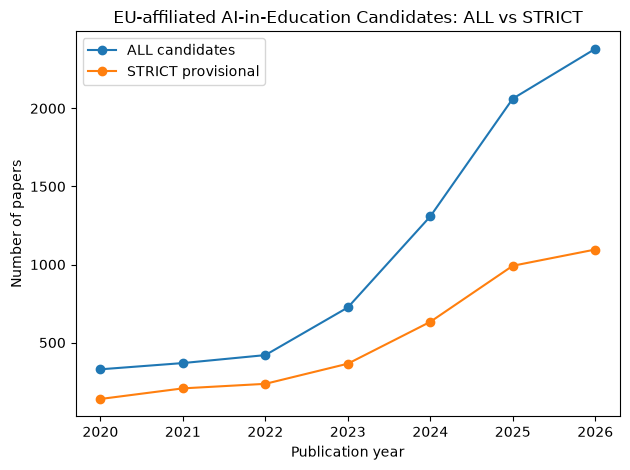

In [91]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project = Path(
    r"C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d"
)

all_file = project / "data" / "processed" / "openalex_relevance_screened.csv"
strict_file = project / "data" / "processed" / "strict_scopus_provisional.csv"
output_dir = project / "data" / "processed"

all_df = pd.read_csv(all_file)
strict_df = pd.read_csv(strict_file)

# Compare candidate counts by publication year
all_year = all_df.dropna(subset=["year"]).groupby("year").size()
strict_year = strict_df.dropna(subset=["year"]).groupby("year").size()

year_comparison = pd.concat(
    [
        all_year.rename("ALL_candidates"),
        strict_year.rename("STRICT_provisional"),
    ],
    axis=1,
).fillna(0).astype(int).sort_index()

year_comparison.to_csv(output_dir / "all_vs_strict_by_year.csv")

print("ALL candidates:", len(all_df))
print("STRICT provisional:", len(strict_df))
display(year_comparison)

# Plot the comparison
ax = year_comparison.plot(kind="line", marker="o")
ax.set_title("EU-affiliated AI-in-Education Candidates: ALL vs STRICT")
ax.set_xlabel("Publication year")
ax.set_ylabel("Number of papers")
ax.legend(["ALL candidates", "STRICT provisional"])
plt.tight_layout()
plt.show()


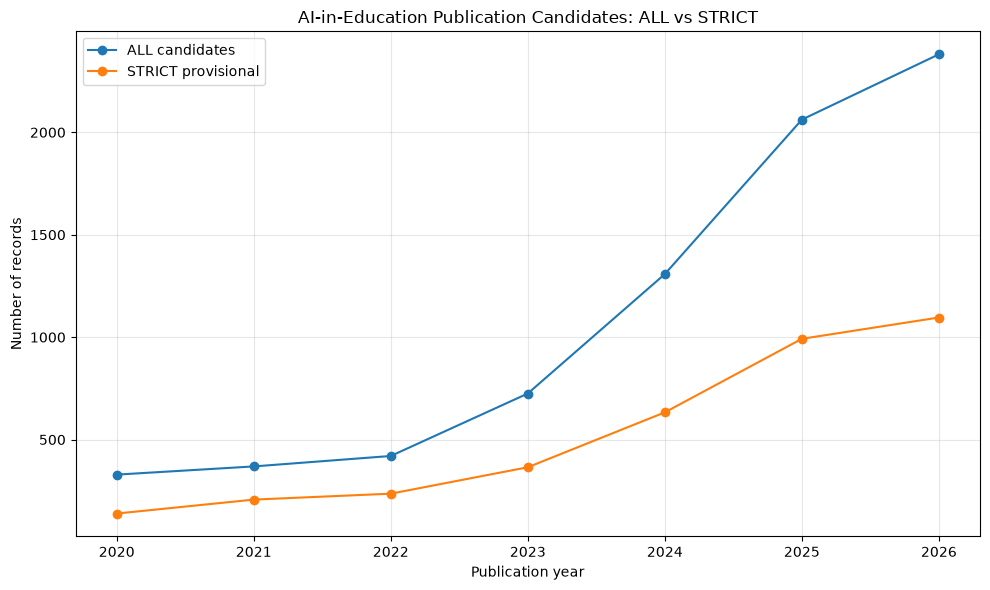

Chart saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\all_vs_strict_by_year.png


In [92]:
import matplotlib.pyplot as plt

chart = year_comparison[["ALL_candidates", "STRICT_provisional"]]

ax = chart.plot(
    kind="line",
    marker="o",
    figsize=(10, 6)
)

ax.set_title("AI-in-Education Publication Candidates: ALL vs STRICT")
ax.set_xlabel("Publication year")
ax.set_ylabel("Number of records")
ax.legend(["ALL candidates", "STRICT provisional"])
ax.grid(True, alpha=0.3)

plt.tight_layout()

chart_path = output_dir / "all_vs_strict_by_year.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

In [93]:
import pandas as pd
import matplotlib.pyplot as plt

# Load your EU candidate dataset
eu_file = project / "data" / "processed" / "openalex_eu_candidates.csv"
eu_df = pd.read_csv(eu_file)

# Each paper may contain multiple EU country codes, separated by semicolons
country_df = eu_df.dropna(subset=["eu_countries"]).copy()

country_df["country"] = country_df["eu_countries"].str.split(";")
country_df = country_df.explode("country")

country_df["country"] = country_df["country"].str.strip()
country_df = country_df[country_df["country"] != ""]

# Count papers associated with each country
country_counts = (
    country_df.groupby("country")["openalex_id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("paper_count")
    .reset_index()
)

# Save the results
country_output = (
    project / "data" / "processed" / "publication_counts_by_country.csv"
)
country_counts.to_csv(country_output, index=False)

display(country_counts.head(10))

print("Total countries found:", country_counts["country"].nunique())
print("Saved to:", country_output)

,country,paper_count
0,DE,1382
1,ES,1137
2,IT,908
3,FR,560
4,GR,481
5,NL,473
6,FI,418
7,SE,405
8,PT,365
9,RO,342


Total countries found: 27
Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\publication_counts_by_country.csv


In [94]:
import pandas as pd

strict_file = (
    project / "data" / "processed"
    / "strict_scopus_provisional.csv"
)

strict_df = pd.read_csv(strict_file)

print("Total rows:", len(strict_df))
print("Duplicate OpenAlex IDs:", strict_df["openalex_id"].duplicated().sum())
print("Missing titles:", strict_df["title"].isna().sum())
print("Missing years:", strict_df["year"].isna().sum())

print("\nPublication year range:")
print(strict_df["year"].min(), "-", strict_df["year"].max())

print("\nScopus coverage status:")
print(strict_df["scopus_coverage_status"].value_counts(dropna=False))

display(strict_df.head())

Total rows: 3668
Duplicate OpenAlex IDs: 0
Missing titles: 1
Missing years: 0

Publication year range:
2020 - 2026

Scopus coverage status:
scopus_coverage_status
Year covered    3668
Name: count, dtype: int64


,openalex_id,title,year,type,doi,eu_countries,eu_country_count,venue,openalex_source_type,openalex_issns,scopus_match,scopus_match_count,scopus_source_titles,scopus_statuses,scopus_coverages,scopus_source_types,scopus_coverage_status
0,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,article,https://doi.org/10.1007/s10639-022-11316-w,FI,1,Education and Information Technologies,journal,13602357; 15737608,True,2,Education and Information Technologies,Active,2005-2026; 1996-2002,Journal,Year covered
1,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,article,https://doi.org/10.1109/tlt.2023.3314610,IE,1,IEEE Transactions on Learning Technologies,journal,19391382; 23720050,True,1,IEEE Transactions on Learning Technologies,Active,2008-2026,Journal,Year covered
2,https://openalex.org/W4399332765,Artificial Intelligence in Education: Implicat...,2024,article,https://doi.org/10.1007/s10758-024-09747-0,DE;FR;IE;IT;NL,5,Technology Knowledge and Learning,journal,22111662; 22111670,True,2,"Technology, Knowledge and Learning",Active,2011-2026,Journal,Year covered
3,https://openalex.org/W4309082440,"The threat, hype, and promise of artificial in...",2022,article,https://doi.org/10.1007/s44163-022-00039-z,SE,1,Discover Artificial Intelligence,journal,27310809,True,1,Discover Artificial Intelligence,Active,2021-2026,Journal,Year covered
4,https://openalex.org/W4392394652,Generative Artificial Intelligence in Educatio...,2024,article,https://doi.org/10.9781/ijimai.2024.02.011,ES,1,International Journal of Interactive Multimedi...,journal,19891660,True,1,International Journal of Interactive Multimedi...,Active,2019-2026,Journal,Year covered


In [95]:
import pandas as pd

strict_file = (
    project / "data" / "processed"
    / "strict_scopus_provisional.csv"
)

strict_df = pd.read_csv(strict_file)

quality_report = pd.Series({
    "Total records": len(strict_df),
    "Duplicate OpenAlex IDs": strict_df["openalex_id"].duplicated().sum(),
    "Missing OpenAlex IDs": strict_df["openalex_id"].isna().sum(),
    "Missing titles": strict_df["title"].isna().sum(),
    "Missing years": strict_df["year"].isna().sum(),
    "Missing DOIs": strict_df["doi"].isna().sum(),
    "Records without Scopus match": (~strict_df["scopus_match"].astype(str).str.lower().eq("true")).sum(),
    "Records without year coverage": (~strict_df["scopus_coverage_status"].eq("Year covered")).sum()
})

display(quality_report.to_frame("value"))

report_file = (
    project / "data" / "processed"
    / "strict_quality_report.csv"
)

quality_report.to_csv(report_file, header=True)

print("Quality report saved to:", report_file)

,value
Total records,3668
Duplicate OpenAlex IDs,0
Missing OpenAlex IDs,0
Missing titles,1
Missing years,0
Missing DOIs,21
Records without Scopus match,0
Records without year coverage,0


Quality report saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\strict_quality_report.csv


In [96]:
missing_title = strict_df[
    strict_df["title"].isna()
    | strict_df["title"].astype(str).str.strip().eq("")
]

display(
    missing_title[
        ["openalex_id", "doi", "year", "venue"]
    ]
)

,openalex_id,doi,year,venue
1871,https://openalex.org/W4387494374,https://doi.org/10.11591/ijra.v12i4,2023,IAES International Journal of Robotics and Aut...


In [97]:
import json

target_id = "https://openalex.org/W4387494374"

raw_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

with open(raw_file, "r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)

        if record.get("id") == target_id:
            print("Title:", record.get("title"))
            print("Display name:", record.get("display_name"))
            print("DOI:", record.get("doi"))
            print("Year:", record.get("publication_year"))
            print("Venue:", record.get("primary_location", {}).get("source", {}).get("display_name"))
            break

Title: None
Display name: None
DOI: https://doi.org/10.11591/ijra.v12i4
Year: 2023
Venue: IAES International Journal of Robotics and Automation (IJRA)


In [98]:
import json
import pandas as pd

raw_file = (
    project / "data" / "raw" / "openalex"
    / "openalex_combined_deduplicated.jsonl"
)

output_file = (
    project / "data" / "processed"
    / "paper_institution_affiliations.csv"
)

eu_ids = set(eu_df["openalex_id"].dropna().astype(str))
rows = []

with open(raw_file, "r", encoding="utf-8") as f:
    for line in f:
        record = json.loads(line)
        work_id = record.get("id")

        if work_id not in eu_ids:
            continue

        for authorship in record.get("authorships", []):
            for inst in authorship.get("institutions", []):
                inst_id = inst.get("id")
                inst_name = inst.get("display_name")

                if inst_id and inst_name:
                    rows.append({
                        "openalex_id": work_id,
                        "title": record.get("title") or record.get("display_name"),
                        "year": record.get("publication_year"),
                        "institution_id": inst_id,
                        "institution": inst_name,
                        "country_code": inst.get("country_code")
                    })

affiliations_df = pd.DataFrame(rows)

affiliations_df = affiliations_df.drop_duplicates(
    subset=["openalex_id", "institution_id"]
)

affiliations_df.to_csv(output_file, index=False)

print("Paper-institution rows:", len(affiliations_df))
print("Unique papers:", affiliations_df["openalex_id"].nunique())
print("Unique institutions:", affiliations_df["institution_id"].nunique())
print("Missing institution names:", affiliations_df["institution"].isna().sum())
print("Saved to:", output_file)

display(affiliations_df.head(10))

Paper-institution rows: 21236
Unique papers: 7594
Unique institutions: 5467
Missing institution names: 0
Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\paper_institution_affiliations.csv


,openalex_id,title,year,institution_id,institution,country_code
0,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,https://openalex.org/I98381234,University of Oulu,FI
1,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,https://openalex.org/I41156924,Victoria University of Wellington,NZ
4,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,https://openalex.org/I153904384,University of Languages and International Studies,VN
5,https://openalex.org/W3196708219,Artificial Intelligence in Education,2021,https://openalex.org/I71999127,Universitat de Barcelona,ES
7,https://openalex.org/W3133611467,Artificial Intelligence in Education,2021,https://openalex.org/I7876267,Open University of the Netherlands,NL
8,https://openalex.org/W3133611467,Artificial Intelligence in Education,2021,https://openalex.org/I67789559,Liberty University,US
9,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,https://openalex.org/I4210100923,Munster Technological University,IE
10,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,https://openalex.org/I166337079,Queen Mary University of London,GB
11,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,https://openalex.org/I158749337,Princess Sumaya University for Technology,JO
12,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,https://openalex.org/I60342839,Qatar University,QA


In [99]:
# EU-27 country codes
EU_COUNTRIES = {
    "AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI",
    "FR", "DE", "GR", "HU", "IE", "IT", "LV", "LT", "LU",
    "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"
}

# Keep only EU-based institutions
eu_affiliations_df = affiliations_df[
    affiliations_df["country_code"].isin(EU_COUNTRIES)
].copy()

# Remove duplicate paper-institution relationships
eu_affiliations_df = eu_affiliations_df.drop_duplicates(
    subset=["openalex_id", "institution_id"]
)

# Save the cleaned file
eu_inst_file = (
    project / "data" / "processed"
    / "eu_paper_institution_affiliations.csv"
)

eu_affiliations_df.to_csv(eu_inst_file, index=False)

print("EU paper-institution rows:", len(eu_affiliations_df))
print("Unique papers:", eu_affiliations_df["openalex_id"].nunique())
print("Unique EU institutions:", eu_affiliations_df["institution_id"].nunique())
print("Missing institution country codes:",
      eu_affiliations_df["country_code"].isna().sum())
print("Saved to:", eu_inst_file)

display(eu_affiliations_df.head(10))

EU paper-institution rows: 13879
Unique papers: 7594
Unique EU institutions: 2489
Missing institution country codes: 0
Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\eu_paper_institution_affiliations.csv


,openalex_id,title,year,institution_id,institution,country_code
0,https://openalex.org/W4304943299,Ethical principles for artificial intelligence...,2022,https://openalex.org/I98381234,University of Oulu,FI
5,https://openalex.org/W3196708219,Artificial Intelligence in Education,2021,https://openalex.org/I71999127,Universitat de Barcelona,ES
7,https://openalex.org/W3133611467,Artificial Intelligence in Education,2021,https://openalex.org/I7876267,Open University of the Netherlands,NL
9,https://openalex.org/W4386634686,Data-Driven Artificial Intelligence in Educati...,2023,https://openalex.org/I4210100923,Munster Technological University,IE
20,https://openalex.org/W2600942494,Artificial Intelligence in Education,2020,https://openalex.org/I82767444,Universidad de Málaga,ES
21,https://openalex.org/W3145952927,Artificial Intelligence and Education,2020,https://openalex.org/I166825849,Tampere University,FI
22,https://openalex.org/W3145952927,Artificial Intelligence and Education,2020,https://openalex.org/I111112146,Tallinn University of Technology,EE
23,https://openalex.org/W3145952927,Artificial Intelligence and Education,2020,https://openalex.org/I155660961,University of Turku,FI
24,https://openalex.org/W3145952927,Artificial Intelligence and Education,2020,https://openalex.org/I95220073,University of Lapland,FI
29,https://openalex.org/W4381956096,Artificial Intelligence in Education,2023,https://openalex.org/I178450904,Universidad Nacional de Educación a Distancia,ES


In [101]:
# Count distinct papers associated with each EU institution
institution_summary = (
    eu_affiliations_df
    .groupby(["institution_id", "institution", "country_code"])
    ["openalex_id"]
    .nunique()
    .reset_index(name="paper_count")
    .sort_values("paper_count", ascending=False)
)

# Save the summary
summary_file = (
    project / "data" / "processed"
    / "eu_institution_paper_counts.csv"
)

institution_summary.to_csv(summary_file, index=False)

print("Unique EU institutions:", len(institution_summary))
print("Saved to:", summary_file)

display(institution_summary.head(15))

Unique EU institutions: 2489
Saved to: C:\Users\Aftab bloch\Documents\project\Data-Analytics--project-D\project-d\data\processed\eu_institution_paper_counts.csv


,institution_id,institution,country_code,paper_count
349,https://openalex.org/I175532246,University of Eastern Finland,FI,96
142,https://openalex.org/I1294671590,Centre National de la Recherche Scientifique,FR,93
204,https://openalex.org/I135140700,University of Bonn,DE,86
64,https://openalex.org/I114112103,Leibniz University Hannover,DE,80
2308,https://openalex.org/I62916508,Technical University of Munich,DE,78
2479,https://openalex.org/I98381234,University of Oulu,FI,74
2378,https://openalex.org/I8204097,Ludwig-Maximilians-Universität München,DE,71
5,https://openalex.org/I100930933,University College Dublin,IE,67
383,https://openalex.org/I184999862,Universidad de Salamanca,ES,66
2412,https://openalex.org/I88491126,Bucharest University of Economic Studies,RO,64


In [102]:
from pathlib import Path
import pandas as pd

processed_dir = project / "data" / "processed"

files_to_check = [
    "openalex_eu_candidates.csv",
    "openalex_relevance_screened.csv",
    "strict_scopus_provisional.csv",
    "all_vs_strict_by_year.csv",
    "publication_counts_by_country.csv",
    "paper_institution_affiliations.csv",
    "eu_paper_institution_affiliations.csv",
    "eu_institution_paper_counts.csv",
    "strict_quality_report.csv",
]

results = []

for filename in files_to_check:
    path = processed_dir / filename

    if path.exists():
        try:
            df = pd.read_csv(path)
            results.append({
                "file": filename,
                "status": "Found",
                "rows": len(df),
                "columns": len(df.columns)
            })
        except Exception as e:
            results.append({
                "file": filename,
                "status": f"Read error: {e}",
                "rows": None,
                "columns": None
            })
    else:
        results.append({
            "file": filename,
            "status": "Missing",
            "rows": None,
            "columns": None
        })

file_check = pd.DataFrame(results)
display(file_check)

,file,status,rows,columns
0,openalex_eu_candidates.csv,Found,7594,7
1,openalex_relevance_screened.csv,Found,7594,9
2,strict_scopus_provisional.csv,Found,3668,17
3,all_vs_strict_by_year.csv,Found,7,3
4,publication_counts_by_country.csv,Found,27,2
5,paper_institution_affiliations.csv,Found,21236,6
6,eu_paper_institution_affiliations.csv,Found,13879,6
7,eu_institution_paper_counts.csv,Found,2489,4
8,strict_quality_report.csv,Found,8,2
